# EDA ของ Dataset กลาง: NSL-KDD และ UNSW-NB15

Notebook นี้สำรวจผล Harmonization ของทั้งสองชุดก่อน Feature Engineering โดยยึดแนวทาง EDA ของ NSL-KDD และ UNSW-NB15: ตรวจคุณภาพข้อมูล ดูสัดส่วน label สำรวจฟีเจอร์เชิงหมวดหมู่/ตัวเลข เปรียบเทียบ Normal กับ Attack และวิเคราะห์ correlation พร้อมบันทึกตารางและกราฟ

อ่าน features, labels และ metadata จากโฟลเดอร์ output/harmonized ของแต่ละชุด และเชื่อมตารางด้วย record_id เท่านั้น Notebook นี้ไม่แก้ข้อมูล ไม่เติม missing และไม่ลบ outlier

> **ข้อควรระวัง:** ฟีเจอร์บางกลุ่มมีเฉพาะบาง dataset เช่น packet/TCP details ของ UNSW-NB15 และ content/window features ของ NSL-KDD ดังนั้น missing ของฟีเจอร์เหล่านี้ในอีกชุดเป็นข้อจำกัดของแหล่งข้อมูล ไม่ใช่ record เสีย ส่วน label ใช้สำรวจเท่านั้น ไม่ใช้เป็น input ตอนฝึก Isolation Forest แบบ unsupervised

## 1. ตั้งค่าและอ่าน Harmonized tables

ส่วนนี้ค้นหาโฟลเดอร์โปรเจกต์อัตโนมัติ ตรวจไฟล์สามตาราง และตรวจ record_id ก่อนเชื่อม หากคอลัมน์กลางที่ทั้งสองชุดควรมีหายหรือมี missing จะหยุดให้ตรวจ Harmonization ก่อน แทนการเดาค่าแทน

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display


def find_project_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for folder in (current, *current.parents):
        if (folder / 'data-pipeline' / 'common' / 'build_dataset.ipynb').is_file():
            return folder
    raise FileNotFoundError('หาโฟลเดอร์ CSI_ML_Final ไม่พบ; เปิด notebook จากภายในโปรเจกต์')


PROJECT_ROOT = find_project_root()
PIPELINE_ROOT = PROJECT_ROOT / 'data-pipeline'
OUTPUT_ROOT = PIPELINE_ROOT / 'common' / 'output' / 'eda'
GRAPH_DIR = OUTPUT_ROOT / 'graphs'
TABLE_DIR = OUTPUT_ROOT / 'tables'
GRAPH_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = ('NSL-KDD', 'UNSW-NB15')
CORE_COLUMNS = [
    'duration', 'protocol', 'bytes_forward', 'bytes_backward',
    'service_group', 'conn_state_group',
]

thai_candidates = ['Leelawadee UI', 'Leelawadee', 'Tahoma', 'TH Sarabun New', 'Noto Sans Thai']
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
thai_font = next((name for name in thai_candidates if name in installed_fonts), None)
if thai_font is None:
    raise RuntimeError('ไม่พบฟอนต์ภาษาไทย เช่น Tahoma, Leelawadee UI หรือ Noto Sans Thai')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['font.family'] = thai_font
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')


def save_eda_graph(figure, filename):
    path = GRAPH_DIR / filename
    figure.savefig(path, dpi=200, bbox_inches='tight', facecolor='white')
    print('บันทึกกราฟ:', path.relative_to(PROJECT_ROOT))


eda_frames, feature_tables = {}, {}
load_rows = []
for dataset in DATASETS:
    folder = PIPELINE_ROOT / dataset / 'output' / 'harmonized'
    paths = {name: folder / f'{name}.csv' for name in ('features', 'labels', 'metadata')}
    missing = [str(path.relative_to(PROJECT_ROOT)) for path in paths.values() if not path.is_file()]
    if missing:
        raise FileNotFoundError(f'{dataset}: ไม่พบไฟล์ {missing}; รัน harmonization.ipynb ก่อน')

    features, labels, metadata = [
        pd.read_csv(paths[name], low_memory=False)
        for name in ('features', 'labels', 'metadata')
    ]
    for name, table in [('features', features), ('labels', labels), ('metadata', metadata)]:
        if 'record_id' not in table or table['record_id'].isna().any() or table['record_id'].duplicated().any():
            raise ValueError(f'{dataset}/{name}: record_id หาย ว่าง หรือซ้ำ')

    feature_ids = features['record_id'].astype(str).reset_index(drop=True)
    for name, table in [('labels', labels), ('metadata', metadata)]:
        if not feature_ids.equals(table['record_id'].astype(str).reset_index(drop=True)):
            raise ValueError(f'{dataset}: ลำดับ record_id ใน {name} ไม่ตรงกับ features')
    if not metadata['source_dataset'].astype(str).eq(dataset).all():
        raise ValueError(f'{dataset}: source_dataset ใน metadata ไม่ตรงกับชุดข้อมูล')

    missing_core = [column for column in CORE_COLUMNS if column not in features.columns]
    if missing_core:
        raise ValueError(f'{dataset}: ขาดคอลัมน์กลาง {missing_core}')
    core_missing = int(features[CORE_COLUMNS].isna().sum().sum())
    if core_missing:
        raise ValueError(f'{dataset}: พบ missing ในคอลัมน์กลาง {core_missing:,} ช่อง; ตรวจ Harmonization')

    joined = features.merge(labels, on='record_id', validate='one_to_one')
    joined = joined.merge(metadata, on='record_id', validate='one_to_one')
    eda_frames[dataset] = joined
    feature_tables[dataset] = features
    load_rows.append({
        'dataset': dataset,
        'records': len(joined),
        'feature_columns': len(features.columns) - 1,
        'core_missing_cells': core_missing,
    })

all_data = pd.concat(eda_frames.values(), ignore_index=True, sort=False)
all_data['label_binary'] = pd.to_numeric(all_data['label_binary'], errors='coerce')
all_data['traffic_label'] = all_data['label_binary'].map({0: 'Normal', 1: 'Attack'}).fillna('Unknown')

display(pd.DataFrame(load_rows))
print('ฟอนต์กราฟ:', thai_font)
print('โฟลเดอร์ผลลัพธ์:', OUTPUT_ROOT.relative_to(PROJECT_ROOT))

,dataset,records,feature_columns,core_missing_cells
0,NSL-KDD,148517,21,0
1,UNSW-NB15,257673,21,0


ฟอนต์กราฟ: Leelawadee UI
โฟลเดอร์ผลลัพธ์: data-pipeline\common\output\eda


## 2. ภาพรวม คุณภาพ และความพร้อมของคอลัมน์

ตารางภาพรวมเปรียบเทียบจำนวน record และสัดส่วน Normal/Attack ภายในแต่ละแหล่ง ตาราง availability แสดงว่าคอลัมน์เฉพาะกลุ่มมีข้อมูลจากชุดใด การแยกสองกรณีนี้สำคัญ: missing ในฟีเจอร์ร่วมควรตรวจแก้ แต่คอลัมน์ที่ไม่มีใน dataset นั้นเป็นข้อจำกัดของข้อมูลต้นทาง

,dataset,records,harmonized_feature_columns,unique_source_labels,normal_percent,attack_percent,duplicate_record_ids,missing_core_cells
0,NSL-KDD,148517,21,40,51.882,48.118,0,0
1,UNSW-NB15,257673,21,2,36.092,63.908,0,0


,source_dataset,source_split,records
0,NSL-KDD,test,22544
1,NSL-KDD,train,125973
2,UNSW-NB15,test,82332
3,UNSW-NB15,train,175341


dataset,NSL-KDD,UNSW-NB15
feature_group,,
NSL content,100.000,0.000
NSL window,100.000,0.000
TCP details,0.000,100.000
packet statistics,0.000,100.000


,dataset,feature_group,feature,missing_records,missing_percent,availability_flag_percent
9,NSL-KDD,NSL content,nsl_failed_logins,0,0.000,100.000
30,UNSW-NB15,NSL content,nsl_failed_logins,257673,100.000,0.000
7,NSL-KDD,NSL content,nsl_hot,0,0.000,100.000
28,UNSW-NB15,NSL content,nsl_hot,257673,100.000,0.000
8,NSL-KDD,NSL content,nsl_logged_in,0,0.000,100.000
29,UNSW-NB15,NSL content,nsl_logged_in,257673,100.000,0.000
10,NSL-KDD,NSL content,nsl_root_shell,0,0.000,100.000
31,UNSW-NB15,NSL content,nsl_root_shell,257673,100.000,0.000
11,NSL-KDD,NSL window,nsl_count_2s,0,0.000,100.000
32,UNSW-NB15,NSL window,nsl_count_2s,257673,100.000,0.000


C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\3834995758.py:75: UserWarning: Glyph 3607 (\N{THAI CHARACTER THO THAHAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\3834995758.py:75: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\3834995758.py:75: UserWarning: Glyph 3586 (\N{THAI CHARACTER KHO KHAI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\3834995758.py:75: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\3834995758.py:75: UserWarning: Glyph 3621 (\N{THAI CHARACTER LO LING}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\3834995758.py:75: UserWarning: Glyph 3585 (\N{THAI CHARACTER KO KAI}) 

บันทึกกราฟ: data-pipeline\common\output\eda\graphs\00_feature_availability_by_dataset.png


C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3607 (\N{THAI CHARACTER THO THAHAN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3586 (\N{THAI CHARACTER KHO KHAI}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3621

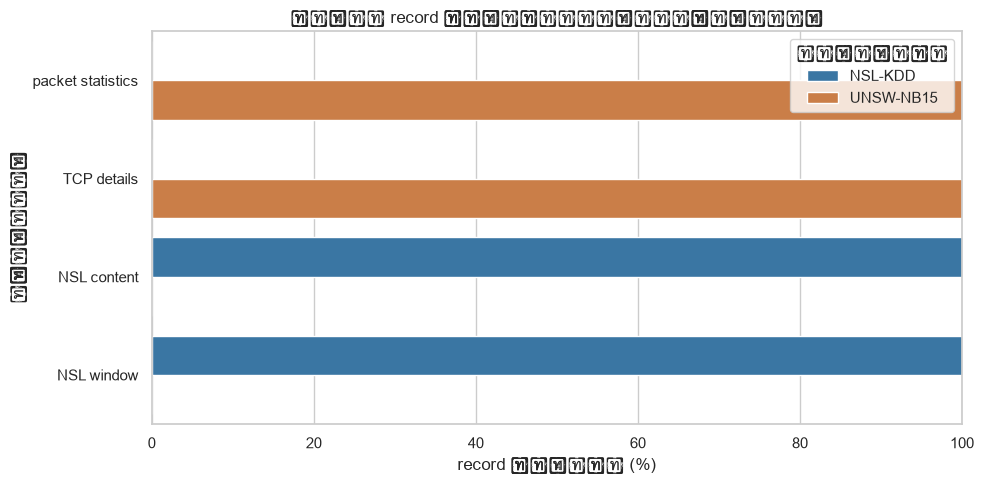

In [2]:
availability_groups = {
    'packet statistics': ('has_packet_stats', ['packets_forward', 'packets_backward', 'mean_packet_size']),
    'TCP details': ('has_tcp_details', ['ttl_forward', 'ttl_backward', 'tcp_window_forward', 'tcp_window_backward']),
    'NSL content': ('has_nsl_content', ['nsl_hot', 'nsl_logged_in', 'nsl_failed_logins', 'nsl_root_shell']),
    'NSL window': ('has_nsl_window', ['nsl_count_2s', 'nsl_srv_count_2s', 'nsl_same_srv_rate_2s', 'nsl_serror_rate_2s']),
}
overview_rows, availability_rows, quality_rows = [], [], []

for dataset, frame in eda_frames.items():
    overview_rows.append({
        'dataset': dataset,
        'records': len(frame),
        'harmonized_feature_columns': len(feature_tables[dataset].columns) - 1,
        'unique_source_labels': frame['label_raw'].astype(str).nunique(),
        'normal_percent': 100 * frame['label_binary'].eq(0).mean(),
        'attack_percent': 100 * frame['label_binary'].eq(1).mean(),
        'duplicate_record_ids': int(frame['record_id'].duplicated().sum()),
        'missing_core_cells': int(frame[CORE_COLUMNS].isna().sum().sum()),
    })

    for group, (flag, columns) in availability_groups.items():
        if flag not in frame:
            raise ValueError(f'{dataset}: metadata ไม่มี availability flag {flag}')
        has_group = frame[flag].fillna(False).astype(bool)
        availability_rows.append({
            'dataset': dataset, 'feature_group': group, 'availability_flag': flag,
            'available_records': int(has_group.sum()), 'available_percent': 100 * has_group.mean(),
        })
        for column in columns:
            if column in feature_tables[dataset]:
                values = feature_tables[dataset][column]
                quality_rows.append({
                    'dataset': dataset, 'feature_group': group, 'feature': column,
                    'missing_records': int(values.isna().sum()),
                    'missing_percent': 100 * values.isna().mean(),
                    'availability_flag_percent': 100 * has_group.mean(),
                })

    for column in CORE_COLUMNS:
        values = feature_tables[dataset][column]
        quality_rows.append({
            'dataset': dataset, 'feature_group': 'shared core', 'feature': column,
            'missing_records': int(values.isna().sum()),
            'missing_percent': 100 * values.isna().mean(),
            'availability_flag_percent': 100.0,
        })

dataset_overview = pd.DataFrame(overview_rows)
availability_summary = pd.DataFrame(availability_rows)
feature_quality = pd.DataFrame(quality_rows)

split_summary = (all_data.groupby(['source_dataset', 'source_split'])
                 .size().rename('records').reset_index())
display(dataset_overview)
display(split_summary)
display(availability_summary.pivot(
    index='feature_group', columns='dataset', values='available_percent'
).round(2))
display(feature_quality.sort_values(['feature_group', 'feature', 'dataset']))

dataset_overview.to_csv(TABLE_DIR / 'dataset_overview.csv', index=False, encoding='utf-8-sig')
split_summary.to_csv(TABLE_DIR / 'source_split_summary.csv', index=False, encoding='utf-8-sig')
availability_summary.to_csv(TABLE_DIR / 'feature_availability.csv', index=False, encoding='utf-8-sig')
feature_quality.to_csv(TABLE_DIR / 'feature_quality.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=availability_summary, x='available_percent', y='feature_group',
    hue='dataset', hue_order=list(DATASETS),
    palette={'NSL-KDD': '#2878B5', 'UNSW-NB15': '#E07A32'}, ax=ax,
)
ax.set(title='สัดส่วน record ที่มีข้อมูลในแต่ละกลุ่มฟีเจอร์',
       xlabel='record ที่มีข้อมูล (%)', ylabel='กลุ่มฟีเจอร์', xlim=(0, 100))
ax.legend(title='แหล่งข้อมูล')
plt.tight_layout()
save_eda_graph(fig, '00_feature_availability_by_dataset.png')
plt.show()

## 3. สัดส่วน label และประเภทการโจมตี

เปรียบเทียบด้วยเปอร์เซ็นต์ภายในแต่ละ dataset เพื่อไม่ให้ชุดที่มีแถวมากกว่ากลบอีกชุด กราฟซ้ายแสดงสัดส่วน Normal/Attack กราฟขวาแสดง attack category เทียบกับ record ทั้งหมดของแหล่งนั้น ตาราง raw label ช่วยตรวจย้อนกลับชื่อ label ต้นฉบับ

,source_dataset,attack_category,records,percent_of_dataset
3,NSL-KDD,Normal,77054,51.882
1,NSL-KDD,DoS/DDoS,53387,35.947
4,NSL-KDD,Probe/Recon,14077,9.478
0,NSL-KDD,Brute-force/R2L,3880,2.612
2,NSL-KDD,Exploit/U2R,119,0.080
9,UNSW-NB15,Normal,93000,36.092
8,UNSW-NB15,Generic/Fuzzer,85794,33.296
7,UNSW-NB15,Exploit/U2R,46036,17.866
6,UNSW-NB15,DoS/DDoS,16353,6.346
10,UNSW-NB15,Probe/Recon,13987,5.428


,source_dataset,label_raw_text,records,percent_of_dataset
16,NSL-KDD,normal,77054,51.882
14,NSL-KDD,neptune,45871,30.886
25,NSL-KDD,satan,4368,2.941
7,NSL-KDD,ipsweep,3740,2.518
27,NSL-KDD,smurf,3311,2.229
20,NSL-KDD,portsweep,3088,2.079
15,NSL-KDD,nmap,1566,1.054
1,NSL-KDD,back,1315,0.885
4,NSL-KDD,guess_passwd,1284,0.865
11,NSL-KDD,mscan,996,0.671


C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1033427638.py:60: UserWarning: Glyph 3649 (\N{THAI CHARACTER SARA AE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1033427638.py:60: UserWarning: Glyph 3627 (\N{THAI CHARACTER HO HIP}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1033427638.py:60: UserWarning: Glyph 3621 (\N{THAI CHARACTER LO LING}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1033427638.py:60: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1033427638.py:60: UserWarning: Glyph 3586 (\N{THAI CHARACTER KHO KHAI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1033427638.py:60: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) m

บันทึกกราฟ: data-pipeline\common\output\eda\graphs\01_labels_and_attack_categories.png


C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3649 (\N{THAI CHARACTER SARA AE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3627 (\N{THAI CHARACTER HO HIP}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3621 (\N{THAI CHARACTER LO LING}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3586 

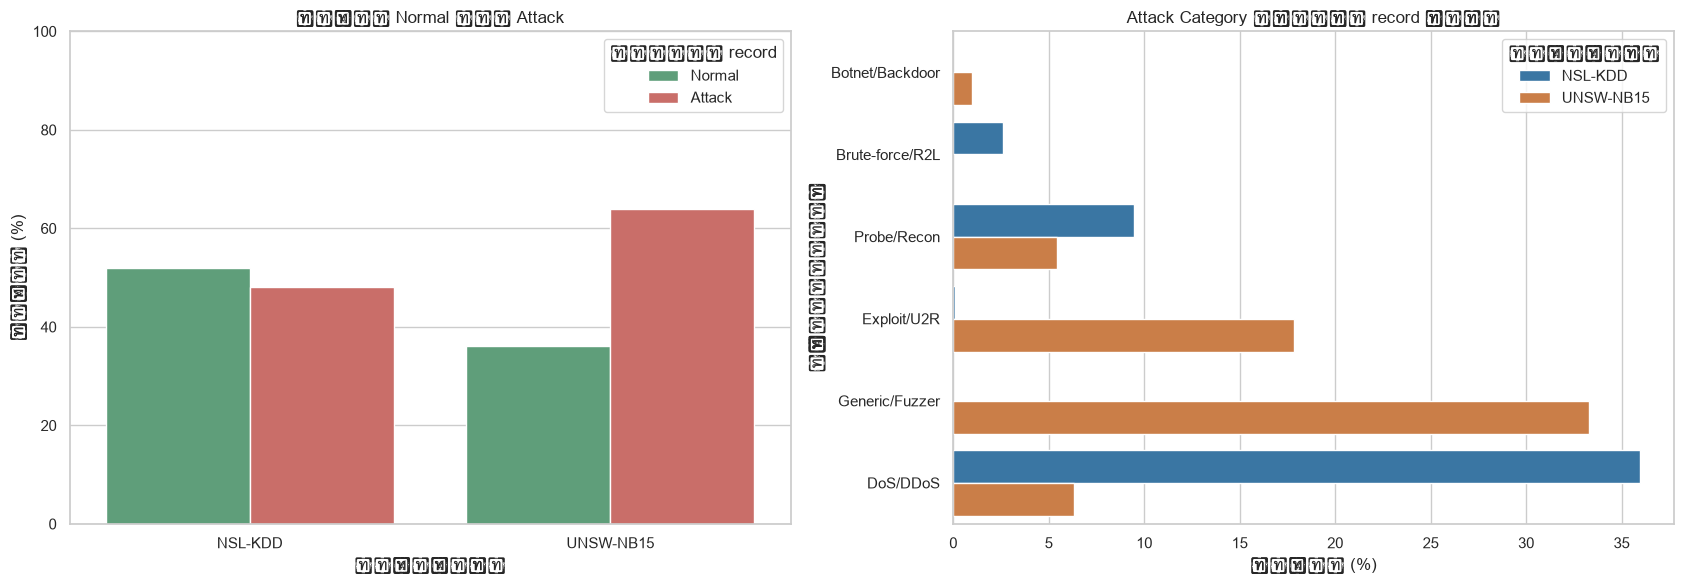

In [3]:
label_summary = (
    all_data.groupby(['source_dataset', 'attack_category'], dropna=False)
    .size().rename('records').reset_index()
)
label_summary['percent_of_dataset'] = (
    100 * label_summary['records']
    / label_summary.groupby('source_dataset')['records'].transform('sum')
)

raw_label_summary = (
    all_data.assign(label_raw_text=all_data['label_raw'].astype(str))
    .groupby(['source_dataset', 'label_raw_text'], dropna=False)
    .size().rename('records').reset_index()
)
raw_label_summary['percent_of_dataset'] = (
    100 * raw_label_summary['records']
    / raw_label_summary.groupby('source_dataset')['records'].transform('sum')
)
display(label_summary.sort_values(['source_dataset', 'records'], ascending=[True, False]))
display(raw_label_summary.sort_values(
    ['source_dataset', 'records'], ascending=[True, False]
).groupby('source_dataset').head(15))
label_summary.to_csv(TABLE_DIR / 'attack_category_summary.csv', index=False, encoding='utf-8-sig')
raw_label_summary.to_csv(TABLE_DIR / 'raw_label_summary.csv', index=False, encoding='utf-8-sig')

binary_summary = (
    all_data.groupby(['source_dataset', 'traffic_label'])
    .size().rename('records').reset_index()
)
binary_summary['percent_of_dataset'] = (
    100 * binary_summary['records']
    / binary_summary.groupby('source_dataset')['records'].transform('sum')
)
attack_categories = label_summary.loc[
    ~label_summary['attack_category'].astype(str).str.lower().eq('normal')
].copy()
category_order = (
    attack_categories.groupby('attack_category')['percent_of_dataset']
    .sum().sort_values().index.tolist()
)
palette = {'NSL-KDD': '#2878B5', 'UNSW-NB15': '#E07A32'}

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.barplot(
    data=binary_summary, x='source_dataset', y='percent_of_dataset',
    hue='traffic_label', order=list(DATASETS), hue_order=['Normal', 'Attack'],
    palette={'Normal': '#54A879', 'Attack': '#D95F59'}, ax=axes[0],
)
axes[0].set(title='สัดส่วน Normal และ Attack',
            xlabel='แหล่งข้อมูล', ylabel='สัดส่วน (%)', ylim=(0, 100))
axes[0].legend(title='ประเภท record')
sns.barplot(
    data=attack_categories, x='percent_of_dataset', y='attack_category',
    hue='source_dataset', order=category_order, hue_order=list(DATASETS),
    palette=palette, ax=axes[1],
)
axes[1].set(title='Attack Category เทียบกับ record ทั้งชุด',
            xlabel='สัดส่วน (%)', ylabel='กลุ่มการโจมตี')
axes[1].legend(title='แหล่งข้อมูล')
plt.tight_layout()
save_eda_graph(fig, '01_labels_and_attack_categories.png')
plt.show()

## 4. เปรียบเทียบ protocol, service และ connection state

สามคอลัมน์นี้มีอยู่ในทั้งสองชุดหลัง Harmonization กราฟใช้เปอร์เซ็นต์ภายในแหล่งและเลือกหมวดที่พบบ่อยเพื่อให้เทียบได้ง่าย ความต่างสะท้อน distribution ของข้อมูลคนละชุด ไม่ได้แปลว่า Harmonization ผิดโดยอัตโนมัติ

,dataset,feature,category,records,percent_of_dataset
9,NSL-KDD,conn_state_group,established,89820,60.478
10,NSL-KDD,conn_state_group,no-reply,36864,24.821
11,NSL-KDD,conn_state_group,reset,20613,13.879
12,NSL-KDD,conn_state_group,other,1220,0.821
24,UNSW-NB15,conn_state_group,established,137298,53.284
25,UNSW-NB15,conn_state_group,no-reply,120271,46.676
26,UNSW-NB15,conn_state_group,reset,84,0.033
27,UNSW-NB15,conn_state_group,other,20,0.008
0,NSL-KDD,protocol,tcp,121569,81.855
1,NSL-KDD,protocol,udp,17614,11.860


C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\2605288955.py:39: UserWarning: Glyph 3626 (\N{THAI CHARACTER SO SUA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\2605288955.py:39: UserWarning: Glyph 3604 (\N{THAI CHARACTER DO DEK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\2605288955.py:39: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\2605288955.py:39: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\2605288955.py:39: UserWarning: Glyph 3616 (\N{THAI CHARACTER PHO SAMPHAO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\2605288955.py:39: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA})

บันทึกกราฟ: data-pipeline\common\output\eda\graphs\02_shared_categorical_distributions.png


C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3626 (\N{THAI CHARACTER SO SUA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3604 (\N{THAI CHARACTER DO DEK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3616 (\N

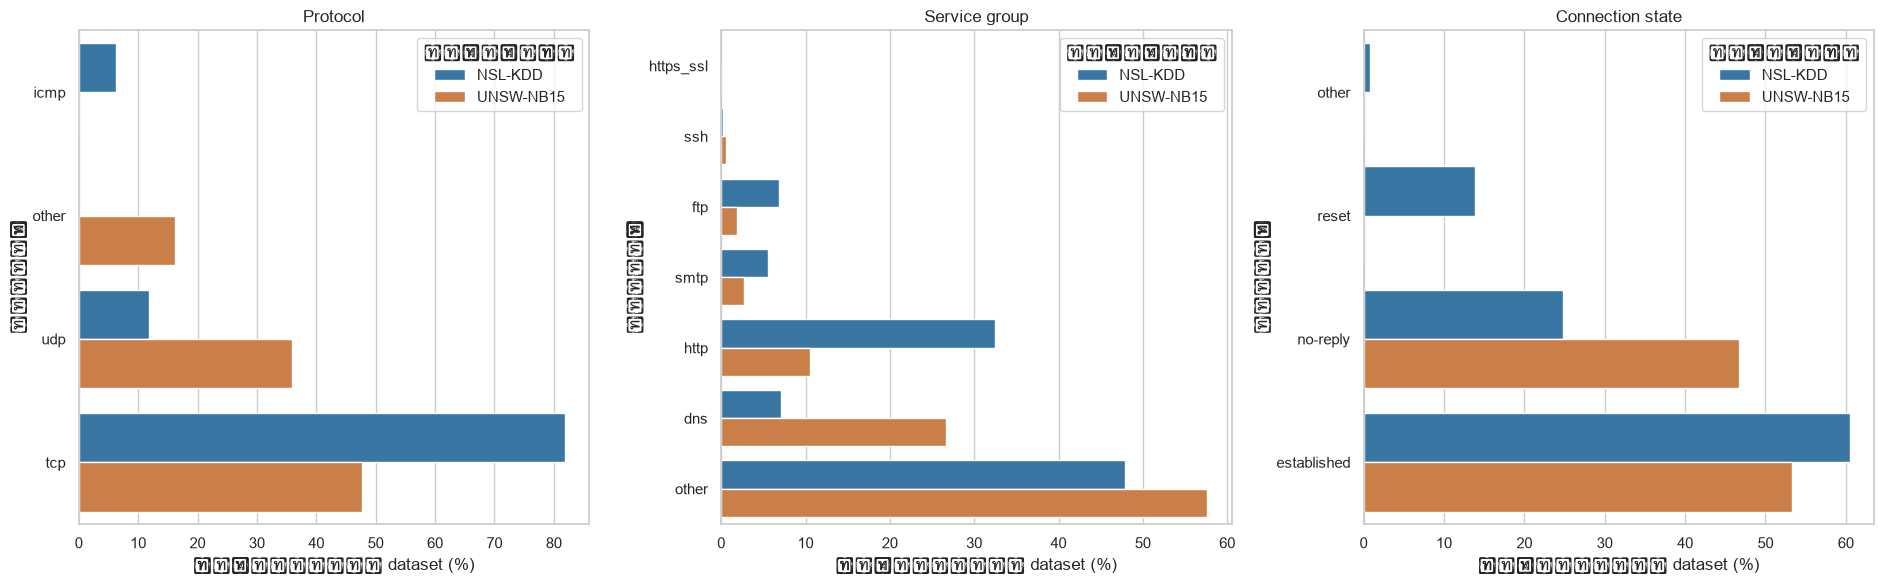

In [4]:
categorical_columns = ['protocol', 'service_group', 'conn_state_group']
category_rows = []
for dataset, frame in eda_frames.items():
    for column in categorical_columns:
        counts = frame[column].fillna('<missing>').astype(str).value_counts(dropna=False)
        for category, records in counts.items():
            category_rows.append({
                'dataset': dataset, 'feature': column,
                'category': category, 'records': int(records),
            })

category_summary = pd.DataFrame(category_rows)
category_summary['percent_of_dataset'] = (
    100 * category_summary['records']
    / category_summary.groupby(['dataset', 'feature'])['records'].transform('sum')
)
display(category_summary.sort_values(
    ['feature', 'dataset', 'records'], ascending=[True, True, False]
))
category_summary.to_csv(TABLE_DIR / 'shared_category_summary.csv', index=False, encoding='utf-8-sig')

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
titles = {
    'protocol': 'Protocol',
    'service_group': 'Service group',
    'conn_state_group': 'Connection state',
}
for ax, column in zip(axes, categorical_columns):
    current = category_summary.loc[category_summary['feature'].eq(column)].copy()
    top = current.groupby('category')['records'].sum().nlargest(10).index.tolist()
    current = current.loc[current['category'].isin(top)]
    order = current.groupby('category')['records'].sum().sort_values().index.tolist()
    sns.barplot(
        data=current, x='percent_of_dataset', y='category', hue='dataset',
        order=order, hue_order=list(DATASETS), palette=palette, ax=ax,
    )
    ax.set(title=titles[column], xlabel='สัดส่วนภายใน dataset (%)', ylabel='หมวดหมู่')
    ax.legend(title='แหล่งข้อมูล')
plt.tight_layout()
save_eda_graph(fig, '02_shared_categorical_distributions.png')
plt.show()

## 5. การกระจาย duration และ bytes

ตารางสถิติใช้ค่าต้นฉบับ ส่วน histogram ใช้ log1p เพื่อบีบหางยาวให้อ่านง่าย การแปลงนี้เกิดเฉพาะตอนวาดกราฟ ไม่ได้แก้ไฟล์ harmonized ค่าเฉลี่ยที่สูงกว่ามัธยฐานมากเป็นสัญญาณว่ามีค่าปลายหาง แต่ไม่ใช่เหตุผลเพียงพอที่จะลบ record

,dataset,feature,count,mean,median,std,q1,q3,q95,max,zero_percent,skew
0,NSL-KDD,duration,148517,276.779,0.000,"2,460.683",0.000,0.000,9.000,"57,715.000",90.881,12.396
1,NSL-KDD,bytes_forward,148517,"40,227.949",44.000,"5,409,611.605",0.000,278.000,"1,594.200","1,379,963,888.000",38.392,206.681
2,NSL-KDD,bytes_backward,148517,"17,088.854",0.000,"3,703,524.780",0.000,571.000,"8,314.000","1,309,937,401.000",52.070,314.937
3,UNSW-NB15,duration,257673,1.247,0.004,5.974,0.000,0.686,2.811,60.000,1.400,8.022
4,UNSW-NB15,bytes_forward,257673,"8,572.952",528.000,"173,773.881",114.000,"1,362.000","13,454.000","14,355,774.000",0.000,47.917
5,UNSW-NB15,bytes_backward,257673,"14,387.288",178.000,"146,199.282",0.000,"1,064.000","33,044.000","14,657,531.000",46.682,44.340


C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:28: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:28: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:28: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:28: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:28: UserWarning: Glyph 3593 (\N{THAI CHARACTER CHO CHING}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:28: UserWarning: Glyph 3610 (\N{THAI CHARACTER BO BAIMA

บันทึกกราฟ: data-pipeline\common\output\eda\graphs\03_shared_numeric_distributions.png


C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3593 

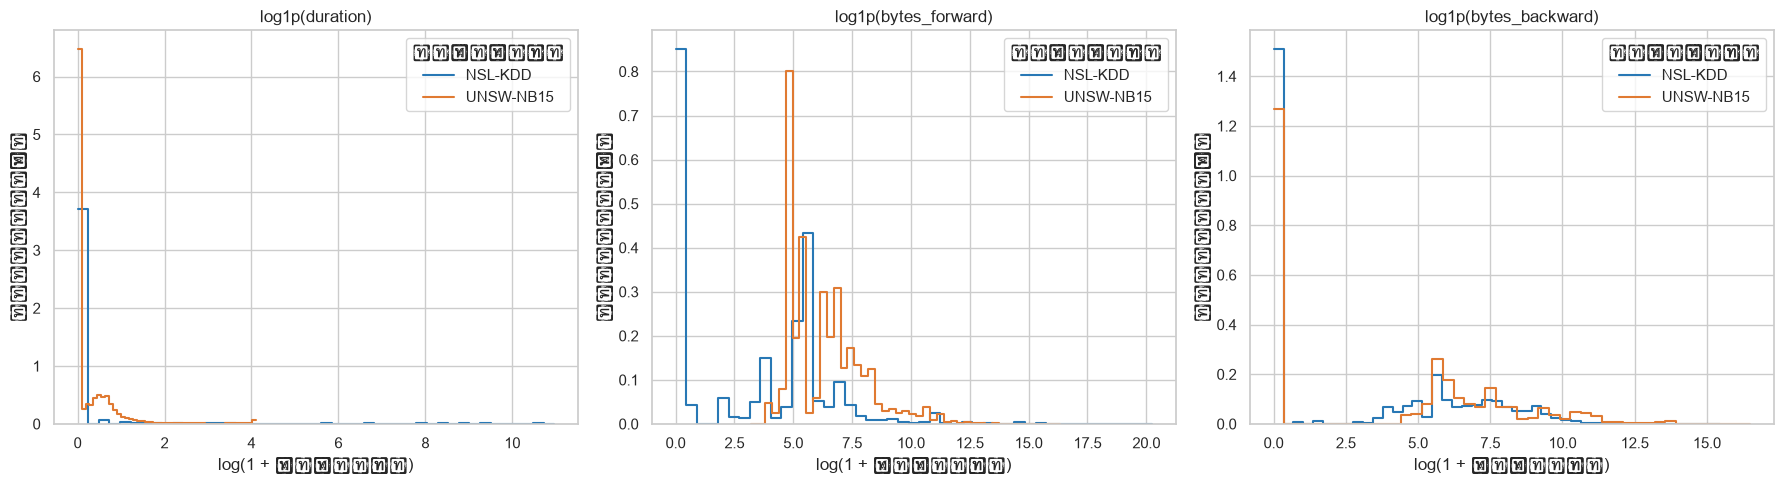

C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:57: UserWarning: Glyph 3611 (\N{THAI CHARACTER PO PLA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:57: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:57: UserWarning: Glyph 3632 (\N{THAI CHARACTER SARA A}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:57: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:57: UserWarning: Glyph 3616 (\N{THAI CHARACTER PHO SAMPHAO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1526167698.py:57: UserWarning: Glyph 3607 (\N{THAI CHARACTER THO THAHA

บันทึกกราฟ: data-pipeline\common\output\eda\graphs\04_normal_vs_attack_shared_features.png


C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3611 (\N{THAI CHARACTER PO PLA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3632 (\N{THAI CHARACTER SARA A}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3616 (\N

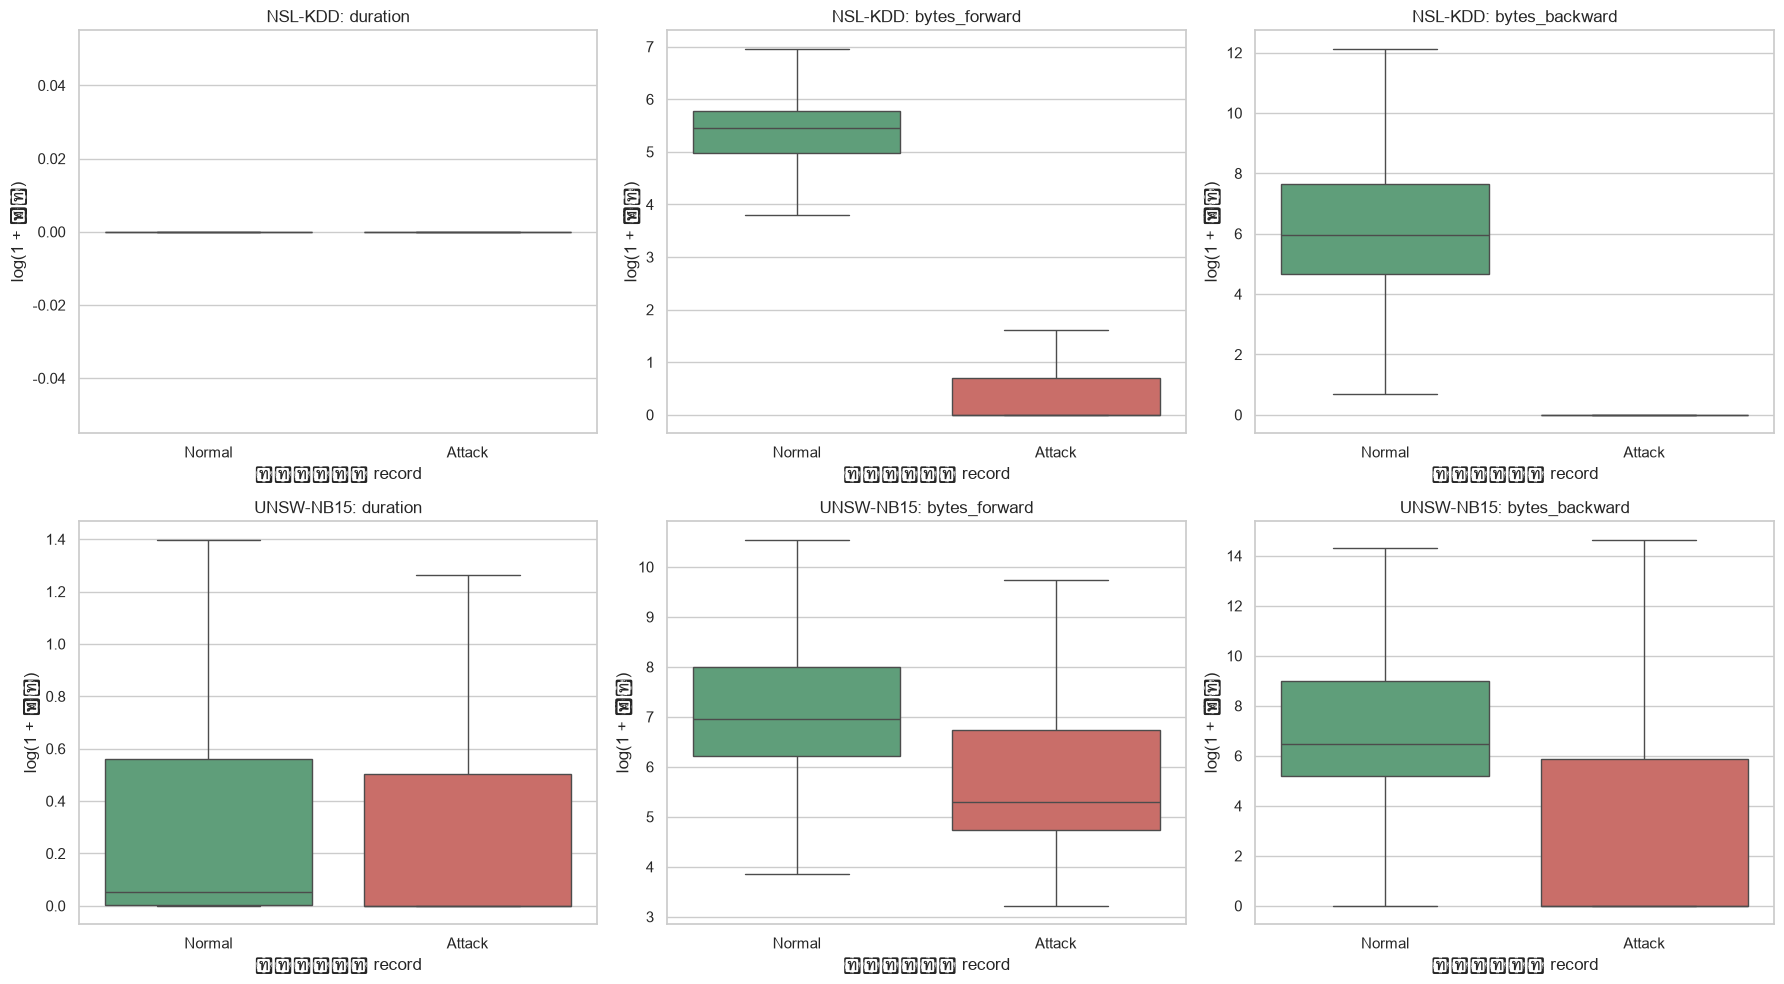

In [5]:
numeric_columns = ['duration', 'bytes_forward', 'bytes_backward']
numeric_rows = []
for dataset, frame in eda_frames.items():
    for column in numeric_columns:
        values = pd.to_numeric(frame[column], errors='coerce').dropna()
        numeric_rows.append({
            'dataset': dataset, 'feature': column, 'count': len(values),
            'mean': values.mean(), 'median': values.median(), 'std': values.std(),
            'q1': values.quantile(.25), 'q3': values.quantile(.75),
            'q95': values.quantile(.95), 'max': values.max(),
            'zero_percent': 100 * values.eq(0).mean(), 'skew': values.skew(),
        })
numeric_summary = pd.DataFrame(numeric_rows)
display(numeric_summary)
numeric_summary.to_csv(TABLE_DIR / 'shared_numeric_summary.csv', index=False, encoding='utf-8-sig')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column in zip(axes, numeric_columns):
    for dataset, frame in eda_frames.items():
        sample = frame[column].sample(n=min(30_000, len(frame)), random_state=42)
        values = np.log1p(pd.to_numeric(sample, errors='coerce').clip(lower=0).dropna())
        sns.histplot(
            values, bins=45, stat='density', element='step', fill=False,
            common_norm=False, color=palette[dataset], label=dataset, ax=ax,
        )
    ax.set(title=f'log1p({column})', xlabel='log(1 + ค่าต้นฉบับ)', ylabel='ความหนาแน่น')
    ax.legend(title='แหล่งข้อมูล')
plt.tight_layout()
save_eda_graph(fig, '03_shared_numeric_distributions.png')
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
traffic_palette = {'Normal': '#54A879', 'Attack': '#D95F59'}
for row, dataset in enumerate(DATASETS):
    frame = eda_frames[dataset].sample(
        n=min(30_000, len(eda_frames[dataset])), random_state=42
    ).copy()
    frame['traffic_label'] = frame['label_binary'].map(
        {0: 'Normal', 1: 'Attack'}
    ).fillna('Unknown')
    for column_index, column in enumerate(numeric_columns):
        plot_data = pd.DataFrame({
            'traffic_label': frame['traffic_label'],
            'log_value': np.log1p(
                pd.to_numeric(frame[column], errors='coerce').clip(lower=0)
            ),
        }).dropna()
        sns.boxplot(
            data=plot_data, x='traffic_label', y='log_value',
            hue='traffic_label', order=['Normal', 'Attack'],
            hue_order=['Normal', 'Attack'], palette=traffic_palette,
            legend=False, showfliers=False, ax=axes[row, column_index],
        )
        axes[row, column_index].set(
            title=f'{dataset}: {column}', xlabel='ประเภท record', ylabel='log(1 + ค่า)'
        )
plt.tight_layout()
save_eda_graph(fig, '04_normal_vs_attack_shared_features.png')
plt.show()

## 6. Correlation แยกตาม dataset

Heatmap ใช้ Pearson correlation ของ log1p(duration/bytes) และ label_binary โดยใช้ช่วงสีเดียวกันทั้งสองชุด ตัวเลขใกล้ +1 หรือ -1 หมายถึงสัมพันธ์เชิงเส้นมากขึ้น ใกล้ 0 หมายถึงสัมพันธ์เชิงเส้นน้อยลง ทั้งหมดเป็นความสัมพันธ์ ไม่ใช่เหตุและผล การใส่ label ในกราฟมีไว้สำรวจเท่านั้น

C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3615 (\N{THAI CHARACTER FO FAN}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\seab

C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1008341609.py:22: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1008341609.py:22: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1008341609.py:22: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1008341609.py:22: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1008341609.py:22: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Windows 10\AppData\Local\Temp\ipykernel_12952\1008341609.py:22: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) mis

บันทึกกราฟ: data-pipeline\common\output\eda\graphs\05_shared_feature_correlation.png


C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3615 (\N{THAI CHARACTER FO FAN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Windows 10\Desktop\CSI_ML_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 3619 (\

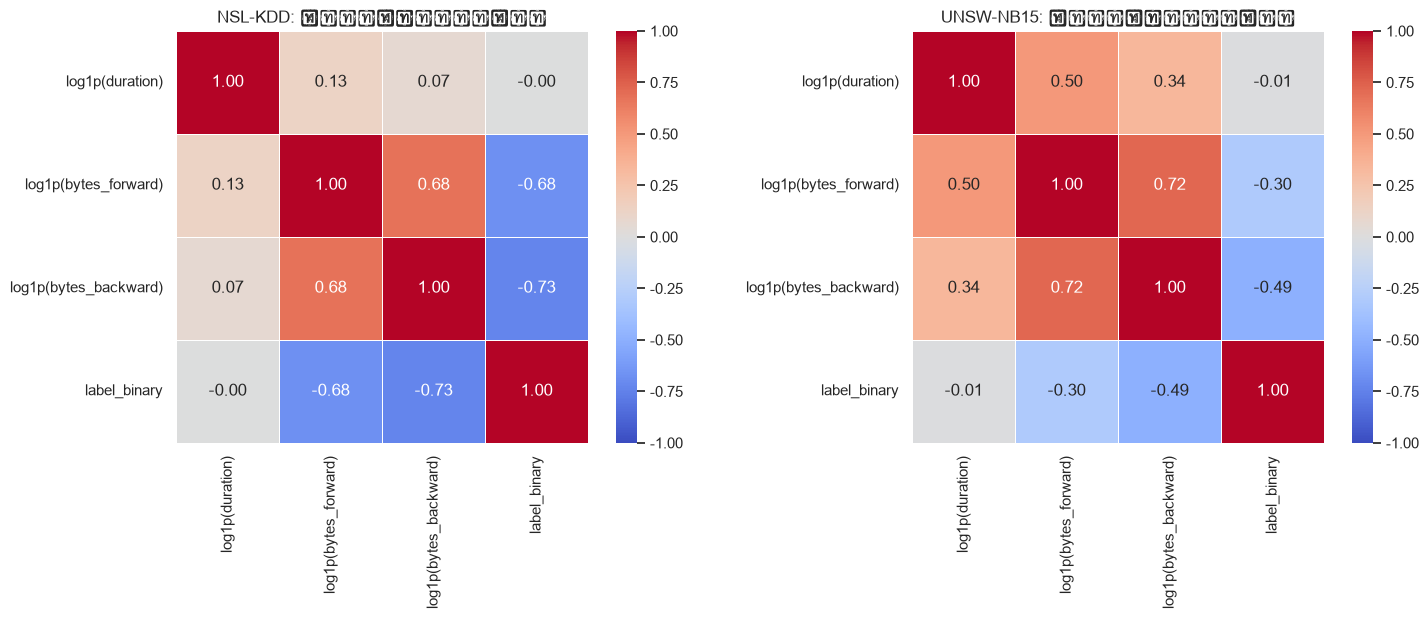

,dataset,feature,pearson_with_label_binary
0,NSL-KDD,duration,-0.004
1,NSL-KDD,bytes_forward,-0.677
2,NSL-KDD,bytes_backward,-0.734
3,UNSW-NB15,duration,-0.012
4,UNSW-NB15,bytes_forward,-0.298
5,UNSW-NB15,bytes_backward,-0.492


In [6]:
correlation_rows = []
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, dataset in zip(axes, DATASETS):
    frame = eda_frames[dataset]
    values = pd.DataFrame(index=frame.index)
    for column in numeric_columns:
        values[f'log1p({column})'] = np.log1p(
            pd.to_numeric(frame[column], errors='coerce').clip(lower=0)
        )
    values['label_binary'] = pd.to_numeric(frame['label_binary'], errors='coerce')
    correlation = values.corr(method='pearson')
    for feature in numeric_columns:
        correlation_rows.append({
            'dataset': dataset, 'feature': feature,
            'pearson_with_label_binary': correlation.loc[f'log1p({feature})', 'label_binary'],
        })
    sns.heatmap(
        correlation, annot=True, fmt='.2f', cmap='coolwarm',
        center=0, vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax,
    )
    ax.set_title(f'{dataset}: ฟีเจอร์ตัวเลขร่วม')
plt.tight_layout()
save_eda_graph(fig, '05_shared_feature_correlation.png')
plt.show()

correlation_summary = pd.DataFrame(correlation_rows)
display(correlation_summary)
correlation_summary.to_csv(
    TABLE_DIR / 'shared_feature_correlation.csv', index=False, encoding='utf-8-sig'
)

## 7. สรุปสิ่งที่ควรนำไปพิจารณา

สรุปนี้ดึงจากผลคำนวณจริงรายแหล่ง การต่างกันของ prevalence และ feature distribution เป็นเรื่องสำคัญสำหรับการทดสอบ cross-dataset ส่วนฟีเจอร์เฉพาะชุดควรคง availability mask ไว้ ไม่เติมศูนย์โดยอัตโนมัติ

In [7]:
print('สรุปจาก Harmonized data:')
for _, row in dataset_overview.iterrows():
    attacks = label_summary.loc[
        label_summary['source_dataset'].eq(row['dataset'])
        & ~label_summary['attack_category'].astype(str).str.lower().eq('normal')
    ]
    dominant = attacks.sort_values('records', ascending=False).head(1)
    dominant_name = dominant.iloc[0]['attack_category'] if not dominant.empty else 'ไม่พบ attack category'
    print(
        f"- {row['dataset']}: {row['records']:,} records; Attack {row['attack_percent']:.2f}%; "
        f"missing ใน core {row['missing_core_cells']:,} ช่อง; กลุ่ม attack ที่มากสุด {dominant_name}"
    )
print('- missing ของฟีเจอร์เฉพาะชุดต้องอ่านร่วมกับ availability flag; อย่าเติม 0 โดยไม่พิจารณาความหมาย')
print('- ความต่างของ label prevalence และ feature distribution เป็น distribution shift ที่ควรทดสอบ ไม่ควรปรับแต่งทิ้งจาก EDA')
print('- label ใช้ประกอบ EDA เท่านั้น ไม่ใช่ input และไม่ใช้ fit Isolation Forest')
print('ตาราง:', TABLE_DIR.relative_to(PROJECT_ROOT))
print('กราฟ:', GRAPH_DIR.relative_to(PROJECT_ROOT))

สรุปจาก Harmonized data:
- NSL-KDD: 148,517 records; Attack 48.12%; missing ใน core 0 ช่อง; กลุ่ม attack ที่มากสุด DoS/DDoS
- UNSW-NB15: 257,673 records; Attack 63.91%; missing ใน core 0 ช่อง; กลุ่ม attack ที่มากสุด Generic/Fuzzer
- missing ของฟีเจอร์เฉพาะชุดต้องอ่านร่วมกับ availability flag; อย่าเติม 0 โดยไม่พิจารณาความหมาย
- ความต่างของ label prevalence และ feature distribution เป็น distribution shift ที่ควรทดสอบ ไม่ควรปรับแต่งทิ้งจาก EDA
- label ใช้ประกอบ EDA เท่านั้น ไม่ใช่ input และไม่ใช้ fit Isolation Forest
ตาราง: data-pipeline\common\output\eda\tables
กราฟ: data-pipeline\common\output\eda\graphs
